# Roots of unity and metric preservation

Reproduces Fig. 2 (Sec. 2.4, Appendices C and E): eigenvalue rings, the plane waves
$\alpha$, the population vector $p$, and the similarity $C$ relative to the origin, for
several symmetry orders $M$ on a single ring.

This is the notebook where the two bases are visible side by side. In the **canonical**
basis the representation is a direct product of planar rotations (App. C),

$$\alpha(x,y) = e^{x\Sigma_x + y\Sigma_y}\alpha_0,\qquad
  \alpha_i = \begin{pmatrix}\cos\Omega_i & -\sin\Omega_i\\ \sin\Omega_i & \cos\Omega_i\end{pmatrix}\alpha_{0,i},
  \qquad \Omega_i = x\lambda_{i,x} + y\lambda_{i,y}$$

so each pair of components is a phase-shifted plane wave — the oscillatory-interference
picture, with no temporal oscillators. The observed population vector is the same thing in
the neuron basis, $p = R^\top\alpha$. Because `block_rotation` is exactly
$\exp(\Sigma)$, $\alpha$ can be built without a matrix exponential at all; the last cell
checks the two routes agree.

**Metric preservation** (App. E) requires the phasor sum to vanish,
$\sum_j e^{2i\phi_j} = 0$. Evenly spaced angles $\phi_j = \pi j/M$ satisfy it for every
$M \ge 2$ but **not** for $M = 1$, which is included below as the counterexample: a single
wavevector gives band-like stripes rather than a grid.

As $M$ grows the ring fills in and the similarity approaches a radial $J_0$ profile — the
single-ring case of the Fourier–Bessel picture in `06_bessel_zeros`.

**Parameters.** The $20\times20$ domain is Appendix A.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.analysis import compute_similarity
from expmap.generators import block_diag_skew, build_generators, roots_of_unity_eigenvalues
from expmap.linalg import block_rotation, random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap
from expmap.plotting import ratemap_collage

# Figure parameters. M = 1 is the counterexample: it fails the phasor condition.
# M = 2 gives square grids, M = 3 hexagonal, and large M approaches a radial profile.
M_VALUES = [1, 2, 3, 20]
N_COPIES = 1
ARENA_SIZE = 10.0  # 20 x 20 domain (Appendix A)
BINS = 64
SEED = 0

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

delta = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS)
DX, DY = np.meshgrid(delta, delta, indexing="ij")
positions = torch.tensor(np.stack([DX.ravel(), DY.ravel()], axis=1), dtype=torch.float32)
extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)

In [2]:
def build(M, n_copies=N_COPIES, seed=SEED):
    """One ring of M roots of unity at unit radius."""
    phi = roots_of_unity_eigenvalues(M, n_copies)
    sigma_x = block_diag_skew(np.cos(phi))
    sigma_y = block_diag_skew(np.sin(phi))

    R = random_orthogonal_matrix(2 * len(phi), seed=seed)
    p0 = starting_state(R)
    Gx, Gy = build_generators(sigma_x, sigma_y, R)
    return ExponentialMap(Gx, Gy), p0, R, phi


print("Metric preservation requires the phasor sum sum_j exp(2i phi_j) to vanish (App. E):")
for M in M_VALUES:
    phi = roots_of_unity_eigenvalues(M, N_COPIES)
    phasor = np.abs(np.sum(np.exp(2j * phi)))
    verdict = "vanishes" if phasor < 1e-10 else "DOES NOT vanish"
    print(f"  M = {M:2d}  N = {2 * len(phi):2d}  |sum| = {phasor:.2e}  -> {verdict}")

Metric preservation requires the phasor sum sum_j exp(2i phi_j) to vanish (App. E):
  M =  1  N =  2  |sum| = 1.00e+00  -> DOES NOT vanish
  M =  2  N =  4  |sum| = 1.22e-16  -> vanishes
  M =  3  N =  6  |sum| = 4.00e-16  -> vanishes
  M = 20  N = 40  |sum| = 8.95e-16  -> vanishes


In [3]:
# Everything Fig. 2 needs, per symmetry order.
results = {}

for M in M_VALUES:
    model, p0, R, phi = build(M)
    N = 2 * len(phi)

    with torch.no_grad():
        p = model(positions, p0).numpy()

    # Canonical basis: alpha = R p. With the canonical p0 the coefficients are uniform.
    alpha = (R.numpy() @ p.T).T
    alpha_0 = (R.numpy() @ p0.numpy())

    ratemaps_p = p.T.reshape(N, BINS, BINS)
    ratemaps_alpha = alpha.T.reshape(N, BINS, BINS)
    similarity = compute_similarity(ratemaps_p, ref_bin=(BINS // 2, BINS // 2))

    results[M] = {
        "phi": phi, "N": N, "p": p, "alpha": alpha, "alpha_0": alpha_0,
        "ratemaps_p": ratemaps_p, "ratemaps_alpha": ratemaps_alpha, "similarity": similarity,
    }
    print(f"M = {M:2d}: N = {N:2d}, alpha_0 uniform at 1/sqrt(N) = {1 / np.sqrt(N):.4f}? "
          f"max deviation {np.abs(alpha_0 - 1 / np.sqrt(N)).max():.2e}")

M =  1: N =  2, alpha_0 uniform at 1/sqrt(N) = 0.7071? max deviation 7.17e-08
M =  2: N =  4, alpha_0 uniform at 1/sqrt(N) = 0.5000? max deviation 5.96e-08
M =  3: N =  6, alpha_0 uniform at 1/sqrt(N) = 0.4082? max deviation 4.47e-08
M = 20: N = 40, alpha_0 uniform at 1/sqrt(N) = 0.1581? max deviation 4.36e-08


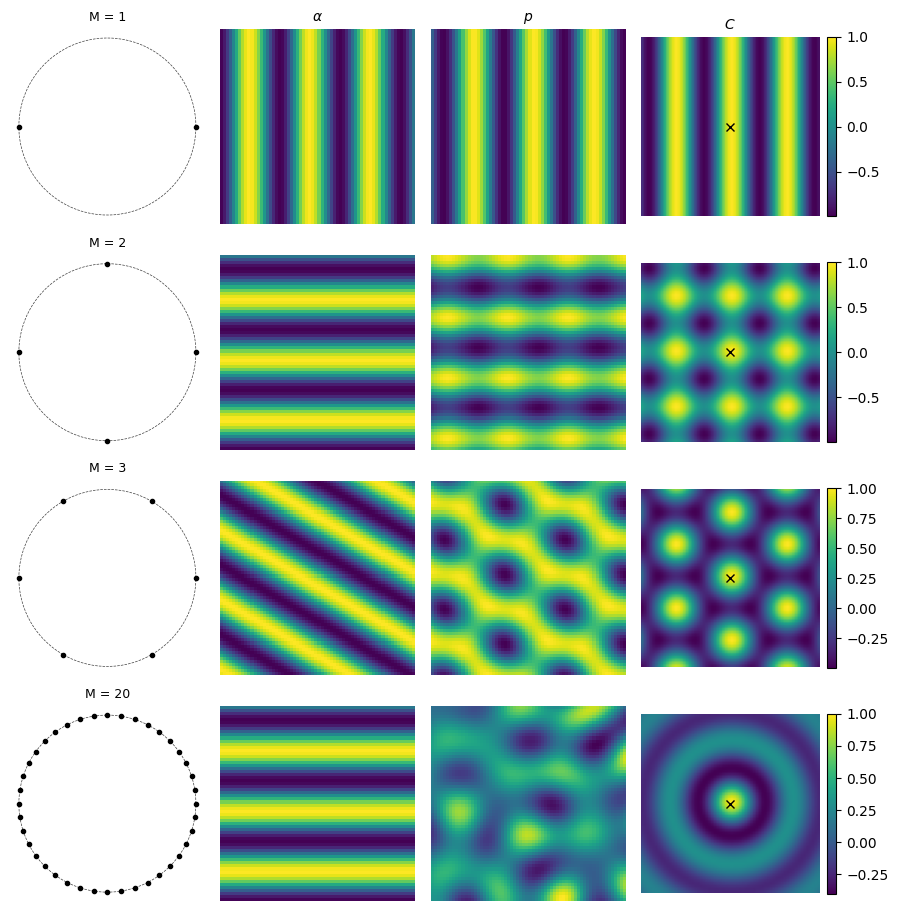

In [4]:
# Fig. 2: rings, plane waves, population vectors, similarity — one row per M.
theta = np.linspace(0, 2 * np.pi, 200)
fig, axs = plt.subplots(len(M_VALUES), 4, figsize=(9, 2.3 * len(M_VALUES)))

for row, M in enumerate(M_VALUES):
    res = results[M]
    phi = res["phi"]

    # Column 1: the eigenvalue ring, each root shown with its conjugate.
    ax = axs[row, 0]
    ax.plot(np.cos(theta), np.sin(theta), "k--", alpha=0.75, linewidth=0.5)
    conjugates = np.concatenate([phi, phi + np.pi])
    ax.plot(np.cos(conjugates), np.sin(conjugates), "ko", markersize=3)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"M = {M}", fontsize=9)

    # Columns 2 and 3: one plane wave, and one neuron built from them. The alpha shown is
    # the middle root, so its orientation varies with M rather than always being phi = 0.
    alpha_index = 2 * (len(phi) // 2)
    for col, (maps, index, label) in enumerate(
        [(res["ratemaps_alpha"], alpha_index, r"$\alpha$"), (res["ratemaps_p"], 0, "$p$")], start=1
    ):
        ax = axs[row, col]
        ax.imshow(maps[index].T, extent=extent, origin="lower", cmap="viridis")
        ax.axis("off")
        if row == 0:
            ax.set_title(label, fontsize=10)

    # Column 4: similarity relative to the origin.
    ax = axs[row, 3]
    im = ax.imshow(res["similarity"].T, extent=extent, origin="lower", cmap="viridis", vmax=1)
    ax.plot(0, 0, "kx", markersize=6)
    ax.axis("off")
    if row == 0:
        ax.set_title("$C$", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "RoU_figure2.svg", dpi=300, transparent=True, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "RoU_figure2.png", dpi=300, transparent=True, bbox_inches="tight")

In [5]:
# The individual panels the original notebook saved, one set per M.
for M in M_VALUES:
    res = results[M]

    plt.figure(figsize=(1, 1))
    plt.title(f"M = {M}")
    plt.plot(np.cos(theta), np.sin(theta), "k--", alpha=0.75, linewidth=0.5)
    conjugates = np.concatenate([res["phi"], res["phi"] + np.pi])
    plt.plot(np.cos(conjugates), np.sin(conjugates), "ko", markersize=1)
    plt.axis("equal")
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"RoU_roots_M={M}.svg", dpi=300, transparent=True, bbox_inches="tight")
    plt.close()

    for maps, suffix in [(res["ratemaps_alpha"], "alpha"), (res["ratemaps_p"], "p")]:
        rows = cols = 1 if len(maps) < 4 else 2
        fig, _ = ratemap_collage(maps, rows=rows, cols=cols, figsize=(1, 1))
        fig.savefig(FIGURE_DIR / f"RoU_M={M}_{suffix}.svg", dpi=300, transparent=True, bbox_inches="tight")
        plt.close(fig)

    plt.figure(figsize=(2, 2))
    plt.imshow(res["similarity"].T, extent=extent, origin="lower", vmax=1)
    plt.plot(0, 0, "kx", markersize=10)
    plt.colorbar(fraction=0.045)
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"RoU_M={M}_sim.svg", dpi=300, transparent=True, bbox_inches="tight")
    plt.close()

print(f"saved panels for M = {M_VALUES}")

saved panels for M = [1, 2, 3, 20]


In [6]:
# Three checks on the basis change this figure is built from.
M = 3
model, p0, R, phi = build(M)
N = 2 * len(phi)
res = results[M]

# 1. block_rotation is the closed form of the canonical-basis evolution, so alpha can be
#    built with no matrix exponential at all (App. C).
alpha_0 = res["alpha_0"]
alpha_closed = np.stack(
    [block_rotation(dx * np.cos(phi) + dy * np.sin(phi)) @ alpha_0 for dx, dy in positions.numpy()]
)
print(f"max |alpha via matrix_exp - alpha via block_rotation| = {np.abs(res['alpha'] - alpha_closed).max():.2e}")

# 2. p and alpha are the same object in two bases.
print(f"max |p - R^T alpha|                                   = "
      f"{np.abs(res['p'] - (R.numpy().T @ res['alpha'].T).T).max():.2e}")

# 3. The similarity is Eq. 4, and with uniform alpha_0 it does not depend on R at all.
d = delta[:, None] - delta[BINS // 2]
dy_ = delta[None, :] - delta[BINS // 2]
closed_form = sum((2 / N) * np.cos(np.cos(phi[i]) * d + np.sin(phi[i]) * dy_) for i in range(len(phi)))
print(f"max |empirical similarity - Eq. 4|                    = "
      f"{np.nanmax(np.abs(res['similarity'] - closed_form)):.2e}")

_, p0_alt, R_alt, _ = build(M, seed=SEED + 1)
with torch.no_grad():
    p_alt = build(M, seed=SEED + 1)[0](positions, p0_alt).numpy()
similarity_alt = compute_similarity(p_alt.T.reshape(N, BINS, BINS), ref_bin=(BINS // 2, BINS // 2))
print(f"max |similarity(R) - similarity(R')|                  = "
      f"{np.nanmax(np.abs(res['similarity'] - similarity_alt)):.2e}  (R-invariance)")

max |alpha via matrix_exp - alpha via block_rotation| = 2.28e-06
max |p - R^T alpha|                                   = 1.79e-07
max |empirical similarity - Eq. 4|                    = 1.60e-06
max |similarity(R) - similarity(R')|                  = 2.06e-06  (R-invariance)
